# Лабораторная работа №3 «Кластеризация»

Цель — разделить двумерную выборку на 15 кластеров методами KMeans,
AgglomerativeClustering и DBSCAN и сравнить результаты.

In [1]:
%pip install -q numpy==1.26.4 scikit-learn==1.6.1

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import cluster
from sklearn import metrics

## Данные

In [2]:
points = np.loadtxt("s1.txt")
print("Количество точек:", len(points))

Количество точек: 5000


## Построение графиков

In [ ]:
def plot_clusters(points, labels, title):
    plt.figure(figsize=(9, 7))
    colors = plt.get_cmap("tab20")
    for label in np.unique(labels):
        group = points[labels == label]
        if label == -1:
            plt.scatter(
                group[:, 0], group[:, 1], s=15,
                color="gray", marker="x", label="Шум"
            )
        else:
            plt.scatter(
                group[:, 0], group[:, 1], s=10,
                color=colors(int(label)), label=f"Кластер {label + 1}"
            )
    plt.title(title)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis("equal")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()

## Кластеризация

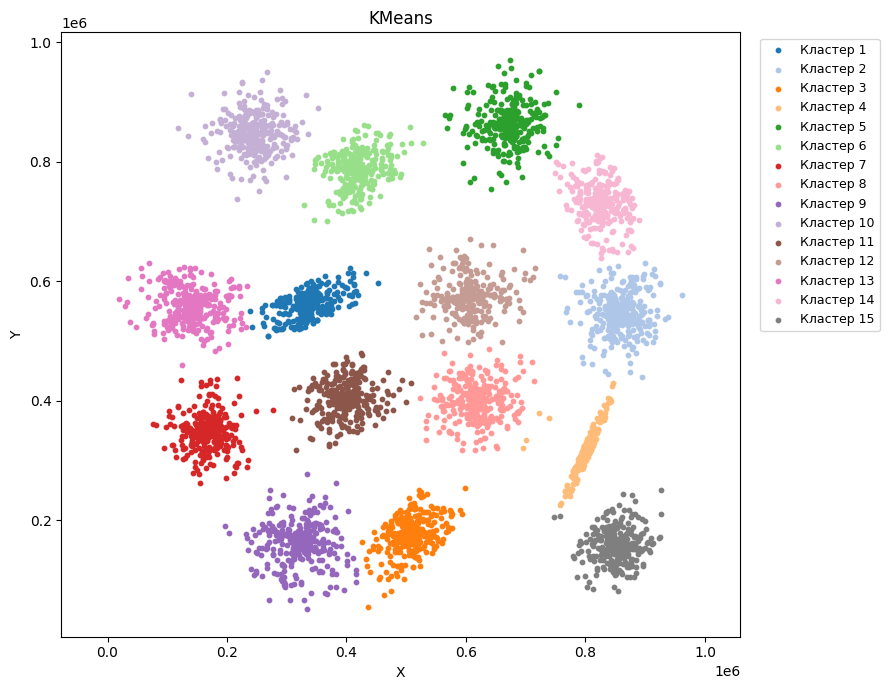

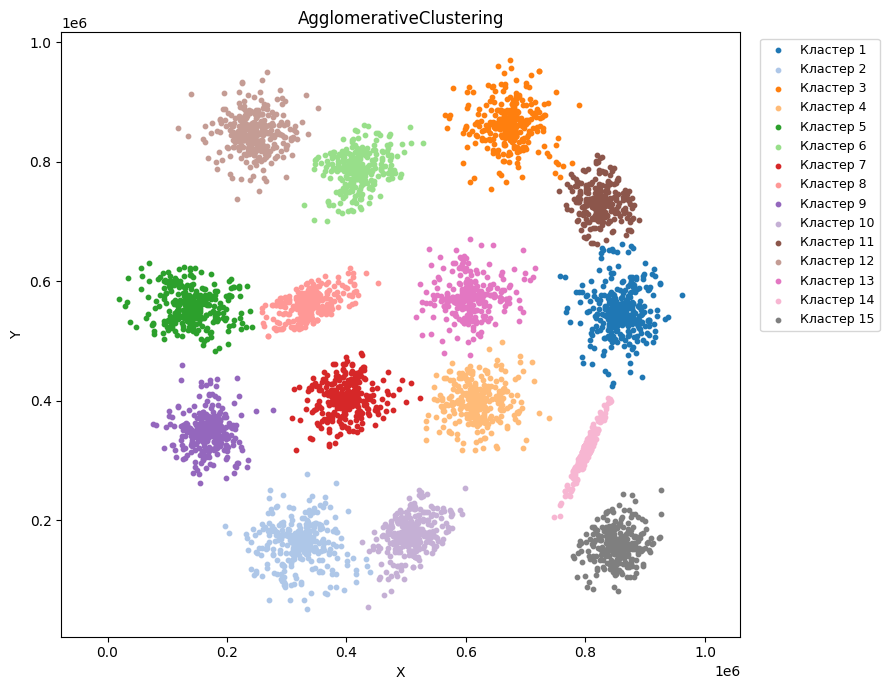

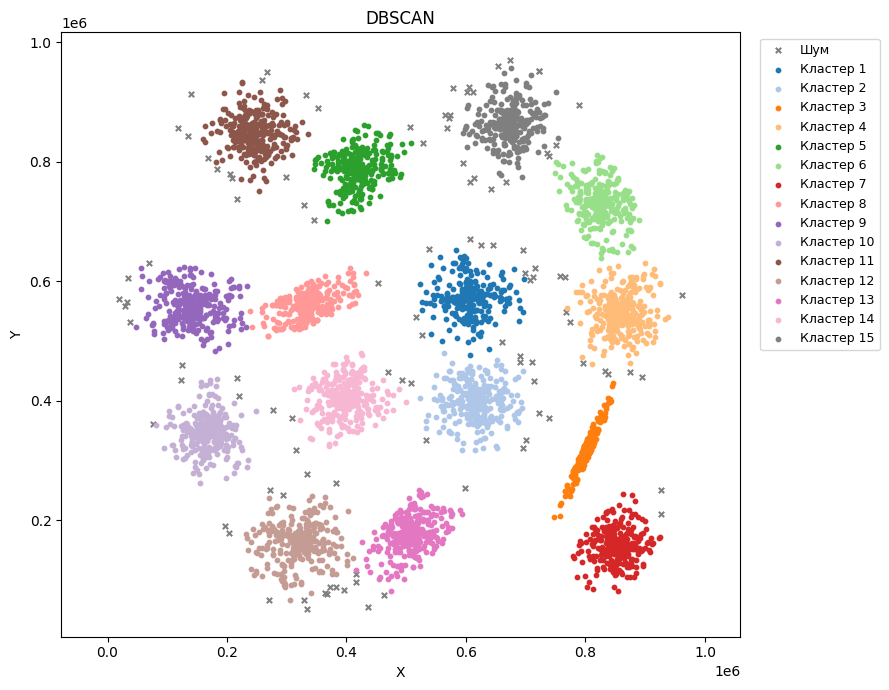

In [4]:
models = {
    "KMeans": cluster.KMeans(n_clusters=15, random_state=67, n_init=10),
    "AgglomerativeClustering": cluster.AgglomerativeClustering(
        n_clusters=15, linkage="ward"
    ),
    "DBSCAN": cluster.DBSCAN(eps=27500, min_samples=10),
}
results = {}

for name, model in models.items():
    labels = model.fit_predict(points)
    results[name] = labels
    plot_clusters(points, labels, name)

## Сравнение результатов

In [7]:
print(f"{'Метод':<25} | {'Кластеры':>8} | {'Шум':>8} | {'Силуэт':>8}")
for name, labels in results.items():
    mask = labels != -1
    cluster_count = len(np.unique(labels[mask]))
    noise_count = np.sum(labels == -1)
    score = metrics.silhouette_score(points[mask], labels[mask])
    print(f"{name:<25} | {cluster_count:>8} | {noise_count:>8} | {score:>8.3f}")

Метод                     | Кластеры |      Шум |   Силуэт
KMeans                    |       15 |        0 |    0.711
AgglomerativeClustering   |       15 |        0 |    0.709
DBSCAN                    |       15 |      108 |    0.725


## Выводы

Все три метода выделили 15 кластеров. На графиках основные группы совпадают,
но принадлежность отдельных точек на границах различается. Видны как округлые,
так и вытянутые группы; при выбранных параметрах все методы разделили их.

KMeans и AgglomerativeClustering распределили все 5000 точек по кластерам.
Их силуэты близки: 0,711 и 0,709 соответственно. Это согласуется с визуально
похожими результатами; небольшая разница не означает существенного превосходства.

DBSCAN отнёс 108 точек (2,16%) к шуму, преимущественно на периферии групп.
Силуэт оставшихся 4892 точек равен 0,725. Его увеличение частично связано
с исключением периферийных точек, поэтому это не доказательство лучшей
кластеризации всей выборки.

Для этой выборки с компактными группами KMeans — подходящий простой метод.
Иерархическая кластеризация полезна, когда важна структура объединений.
DBSCAN полезен при наличии шума и групп сложной формы, если их плотности сопоставимы.